<img src="https://complexsystemsintelligence.github.io/biztonsagkritikus-rendszerek/gyakorlat/assets/logo/pe-cimer-nevjel-fekvo-kek.png" alt="Pannon Egyetem – University of Pannonia" height="56">

[Megnyitás a Google Colabban](https://colab.research.google.com/github/ComplexSystemsIntelligence/biztonsagkritikus-rendszerek/blob/main/gyakorlat/notebookok/06_megbizhatosag_weibull.ipynb) · *Biztonságkritikus rendszerek – gyakorlati útmutató* · © 2026 Abonyi János, Pannon Egyetem · kód: MIT, szöveg: CC BY-NC-SA 4.0

# 6. gyakorlat – meghibásodási ráta és Weibull-elemzés

A notebook a könyv 8. fejezetének két esetét számolja végig: (1) állandó meghibásodási ráta becslése terepi adatokból konfidenciakorlátokkal, (2) Weibull-illesztés cenzúrázott csapágyadatokra maximum likelihood és rangregresszió módszerrel, bootstrap-konfidenciaintervallummal.

**Tanulási eredmények:** pont- és intervallumbecslés exponenciális modellre; Weibull-paraméterek becslése jobbról cenzúrázott adatokból; a becslési bizonytalanság számszerűsítése.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
PE = {"kek": "#285780", "sotet": "#1B3A57", "kiemel": "#E07B39", "zold": "#3E8E63", "piros": "#B83A3A", "lila": "#7A5C99", "szurke": "#6B7280"}
plt.rcParams.update({"figure.figsize": (7.5, 4.2), "axes.grid": True, "grid.color": "#e6e9ee", "axes.spines.top": False,
                     "axes.spines.right": False, "axes.prop_cycle": plt.cycler(color=list(PE.values())), "axes.formatter.use_locale": False})
def hu(x, sig=3):
    """Szám magyar formátumban (tizedesvessző, normálalak)."""
    if x == 0: return "0"
    e = int(np.floor(np.log10(abs(x))))
    if -2 <= e < 5: return f"{x:.{max(0, sig-1-e)}f}".replace(".", ",")
    return f"{x/10**e:.{sig-1}f}".replace(".", ",") + f"·10^{e}"
from scipy import optimize, special

## 1. Állandó ráta terepi adatokból

250 távadó 4 éven át: $T = 250 \cdot 4 \cdot 8760 = 8{,}76\cdot10^6$ óra, $r = 3$ veszélyes meghibásodás. A pontbecslés $\hat\lambda = r/T$, az egyoldali $1-\alpha$ felső korlát $\chi^2_{1-\alpha}(2r+2)/(2T)$.

In [2]:
T, r = 250*4*8760, 3
print("pontbecslés:", hu(r/T), "1/h")
for c in (0.7, 0.9, 0.95):
    print(f"{int(c*100)} %-os felső korlát: {hu(stats.chi2.ppf(c, 2*r+2)/(2*T))} 1/h")

pontbecslés: 3,42·10^-7 1/h
70 %-os felső korlát: 5,44·10^-7 1/h
90 %-os felső korlát: 7,63·10^-7 1/h
95 %-os felső korlát: 8,85·10^-7 1/h


A 70%-os felső korlát ($5{,}44\cdot10^{-7}$) az IEC 61508 2H útjának adatkövetelménye. **1. feladat:** mennyi üzemóra kellene ahhoz, hogy hibamentes működés esetén a 90%-os felső korlát $10^{-7}$/h legyen?

## 2. Weibull-illesztés cenzúrázott adatokra

A KoboCella robothajtásainak csapágyai: kilenc meghibásodás és három, 12 000 óránál még működő (jobbról cenzúrázott) csapágy.

In [3]:
t = np.array([4100, 5200, 5900, 6600, 7300, 7900, 8500, 9800, 10500, 12000, 12000, 12000], float)
d = np.array([1]*9 + [0]*3)          # 1 = meghibásodott, 0 = cenzúrázott
def negll(p):
    b, e = np.exp(p)
    z = (t/e)**b
    return -(np.sum(d*(np.log(b) - np.log(e) + (b-1)*np.log(t/e))) - np.sum(z))
res = optimize.minimize(negll, x0=np.log([2, 10000]), method="Nelder-Mead", options={"xatol": 1e-9, "fatol": 1e-12, "maxiter": 5000})
beta, eta = np.exp(res.x)
mttf = eta*special.gamma(1 + 1/beta)
print(f"ML-becslés: β = {beta:.3f}, η = {eta:.0f} h, MTTF = {mttf:.0f} h")
print(f"B10 = {eta*(-np.log(0.9))**(1/beta):.0f} h, R(5000) = {np.exp(-(5000/eta)**beta):.3f}")
print(f"R(8000 | 6000) = {np.exp(-(8000/eta)**beta + (6000/eta)**beta):.3f}")

ML-becslés: β = 2.731, η = 10172 h, MTTF = 9049 h
B10 = 4462 h, R(5000) = 0.866
R(8000 | 6000) = 0.754


Az eredmény egyezik a könyvvel: $\hat\beta = 2{,}73$, $\hat\eta \approx 10\,170$ h. A $\beta > 1$ elhasználódásra utal: a megelőző csere értelmes stratégia.

### Rangregresszió (Weibull-papír)

A rangregresszió a medián rangokat ($F_i \approx (i - 0{,}3)/(n + 0{,}4)$, cenzúrázott adatoknál Johnson-féle korrigált rangokkal) illeszti egyenesre a $\ln(-\ln(1-F))$ – $\ln t$ síkon.

rangregresszió: β = 3.188, η = 9459 h


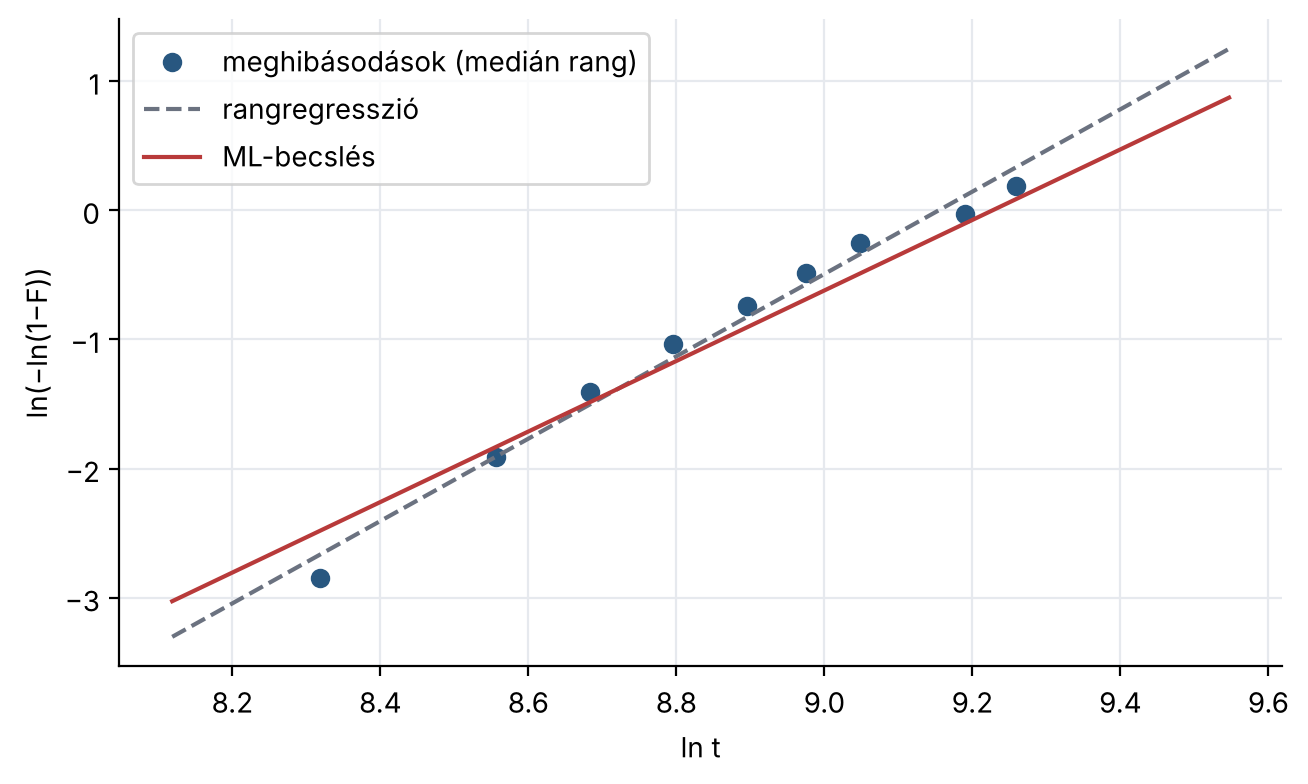

In [4]:
# Johnson-féle korrigált rangok
n = len(t); rang_elozo = 0.0; pontok = []
for i, (ti, di) in enumerate(zip(t, d)):
    if di:
        novekmeny = (n + 1 - rang_elozo)/(1 + (n - i))
        rang_elozo += novekmeny
        pontok.append((ti, (rang_elozo - 0.3)/(n + 0.4)))
x = np.log([p[0] for p in pontok]); y = np.log(-np.log(1 - np.array([p[1] for p in pontok])))
b_rr, a_rr = np.polyfit(x, y, 1)
print(f"rangregresszió: β = {b_rr:.3f}, η = {np.exp(-a_rr/b_rr):.0f} h")
fig, ax = plt.subplots()
ax.plot(x, y, "o", color=PE["kek"], label="meghibásodások (medián rang)")
xs = np.linspace(x.min()-0.2, np.log(14000), 50)
ax.plot(xs, b_rr*xs + a_rr, "--", color=PE["szurke"], label="rangregresszió")
ax.plot(xs, beta*(xs - np.log(eta)), color=PE["piros"], label="ML-becslés")
ax.set_xlabel("ln t"); ax.set_ylabel("ln(−ln(1−F))"); ax.legend(); plt.show()

## 3. Bootstrap-konfidenciaintervallum

Kevés adatnál a becslés bizonytalansága nagy. A parametrikus bootstrap az illesztett modellből új mintákat szimulál (ugyanazzal a cenzúrázási idővel), mindegyikre újra illeszt, és a becslések eloszlásából ad intervallumot.

In [5]:
rng = np.random.default_rng(42)
B = 1000; becslesek = []
for _ in range(B):
    ts = eta*rng.weibull(beta, n)
    ds = (ts < 12000).astype(int); ts = np.minimum(ts, 12000)
    if ds.sum() < 3: continue
    def nll(p, ts=ts, ds=ds):
        b, e = np.exp(p); z = (ts/e)**b
        return -(np.sum(ds*(np.log(b) - np.log(e) + (b-1)*np.log(ts/e))) - np.sum(z))
    r_ = optimize.minimize(nll, x0=np.log([beta, eta]), method="Nelder-Mead")
    becslesek.append(np.exp(r_.x))
becslesek = np.array(becslesek)
for j, nev in enumerate(["β", "η"]):
    lo, hi = np.percentile(becslesek[:, j], [5, 95])
    print(f"{nev}: 90 %-os bootstrap-intervallum {lo:.2f} – {hi:.2f}")

β: 90 %-os bootstrap-intervallum 1.83 – 4.87
η: 90 %-os bootstrap-intervallum 8285.36 – 12322.67


**2. feladat.** Hogyan változik az intervallum szélessége, ha a 12 helyett 36 csapágy adata állna rendelkezésre (ugyanazzal az arányú cenzúrázással)? Módosítsd a szimulációt!

**3. feladat.** Milyen megelőző csereidőköz mellett lesz a csapágy meghibásodási valószínűsége a csere előtt legfeljebb 5%?

## Mintaprompt

*„Az alábbi csapágyadatokra Weibull-eloszlást illesztettem (β = 2,73, η = 10 170 h). Magyarázd el lépésenként, mit jelent a β > 1 a karbantartási stratégia szempontjából, és milyen feltevései vannak a megelőző csere optimalizálásának! Ne számolj helyettem; kérdezz rá, ha valamelyik adat hiányzik.”*